In [ ]:
import sys

# Append the parent dir to search path to allow imports from src
sys.path.append('..')

# NOTE: In a real Python file instead use the line below
# sys.path.append(str(Path(__file__).resolve().parent.parent))

# Tell the Notebook to reload changed code in own packages automatically
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

TRAIN_PATH = Path('../data/raw/train_images/')
TEST_PATH = Path('../data/raw/test_images/')
LABELS_PATH = Path('../data/raw/train.csv')

## Augmentation pipeline

In [ ]:
import albumentations as A

pipeline = A.Compose(
    [
        A.HorizontalFlip(p=0.3),
        A.VerticalFlip(p=0.3),
        A.RandomBrightnessContrast(p=0.8),
        A.Rotate(p=0.6),
    ]
)


## PSPNet for binary image segmentation

After training it should detect if a new image contains any of the 4 cloud types.

In [ ]:
import segmentation_models_pytorch as smp

# model_fpn     = smp.FPN(encoder_name="resnet34", encoder_weights="imagenet", classes=4)
# model_linknet = smp.Linknet(encoder_name="resnet34", encoder_weights="imagenet", classes=4)
model_pspnet = smp.PSPNet(
    encoder_name='resnet34', encoder_weights='imagenet', classes=4
)


## Dataset and DataLoader

`CloudSegmentationDataset` wraps `CloudSegmentationImage`: for every unique
image in `LABELS_PATH` it decodes the per-label masks, runs the `pipeline`
augmentation on the image/masks pair, and returns normalized tensors ready
for the model.

The image list is split into train/validation *before* wrapping it in two
dataset instances, so the same augmentation pipeline is used for training
while validation always sees the un-augmented image.

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

from src.data.cloud_segmentation_dataset import CloudSegmentationDataset
from src.data.labels import load_processed_labels

labels_df = load_processed_labels(LABELS_PATH)

# Get all image names. NOTE: Every image has 4 rows in labels_df, so `.unique()`
# must be called to only get one item of every name. Additionally `.tolist()`
# is called to convert the result from type `ArrowStringArray`, which
# `train_test_split()` doesn't understand, to a list.
image_names = labels_df['Image'].unique().tolist()

# Split by the unique image name. So all 4 label rows of an image end up on the
# same side of the split (no leakage between train and validation).
train_image_names, val_image_names = train_test_split(
    image_names, test_size=0.2, random_state=42
)

train_labels_df = labels_df[labels_df['Image'].isin(train_image_names)]
val_labels_df = labels_df[labels_df['Image'].isin(val_image_names)]

train_dataset = CloudSegmentationDataset(
    train_labels_df, TRAIN_PATH, pipeline=pipeline
)

# No augmentation for validation, so it reflects real-world performance
val_dataset = CloudSegmentationDataset(val_labels_df, TRAIN_PATH, pipeline=None)

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print(
    f'Train images: {len(train_dataset)}, validation images: {len(val_dataset)}'
)


Train images: 4436, validation images: 1110


## Loss, optimizer, device

A pixel can belong to several cloud types at once (see
`CloudSegmentationImage.get_mask_stack`), so this is a **multi-label**
problem: each of the 4 output channels is an independent binary mask, not a
single softmax over 4 classes. The loss combines `BCEWithLogitsLoss` (per-pixel,
per-channel) with a multilabel Dice loss (rewards overlap of the predicted
and true mask regions), which is a common combination for segmentation.

In [6]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_pspnet = model_pspnet.to(device)

bce_loss = torch.nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode='multilabel', from_logits=True)


def criterion(logits, masks):
    return bce_loss(logits, masks) + dice_loss(logits, masks)


optimizer = torch.optim.Adam(model_pspnet.parameters(), lr=1e-4)

print(f'Using device: {device}')


Using device: cuda


## Train the model

In [7]:
from tqdm.auto import tqdm

NUM_EPOCHS = 15

history = {'train_loss': [], 'val_loss': []}

for epoch in range(NUM_EPOCHS):
    # --- Train ---
    model_pspnet.train()
    train_loss = 0.0
    for images, masks in tqdm(
        train_loader, desc=f'Epoch {epoch + 1}/{NUM_EPOCHS} [train]'
    ):
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model_pspnet(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
    train_loss /= len(train_dataset)

    # --- Validate ---
    model_pspnet.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in tqdm(
            val_loader, desc=f'Epoch {epoch + 1}/{NUM_EPOCHS} [val]'
        ):
            images, masks = images.to(device), masks.to(device)
            logits = model_pspnet(images)
            loss = criterion(logits, masks)
            val_loss += loss.item() * images.size(0)
    val_loss /= len(val_dataset)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    print(
        f'Epoch {epoch + 1}/{NUM_EPOCHS} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f}'
    )


Epoch 1/15 [train]:   0%|          | 0/555 [00:00<?, ?it/s]

c:\Users\uwero\REPOS\Python\jun26_bcds_cloud_segmentation\notebooks\..\src\data\cloud_segmentation_dataset.py:69: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  image_tensor = torch.from_numpy(np.ascontiguousarray(image))


Epoch 1/15 [val]:   0%|          | 0/139 [00:00<?, ?it/s]

Epoch 1/15 - train_loss: 0.9146 - val_loss: 0.9229


Epoch 2/15 [train]:   0%|          | 0/555 [00:00<?, ?it/s]

...

Epoch 14/15 [val]:   0%|          | 0/139 [00:00<?, ?it/s]

Epoch 14/15 - train_loss: 0.7778 - val_loss: 0.7993


Epoch 15/15 [train]:   0%|          | 0/555 [00:00<?, ?it/s]

Epoch 15/15 [val]:   0%|          | 0/139 [00:00<?, ?it/s]

Epoch 15/15 - train_loss: 0.7765 - val_loss: 0.7804


## Save the trained model

In [8]:
from pathlib import Path

import torch

MODEL_PATH = Path('../models/pspnet_resnet34_binary.pth')
torch.save(model_pspnet.state_dict(), MODEL_PATH)


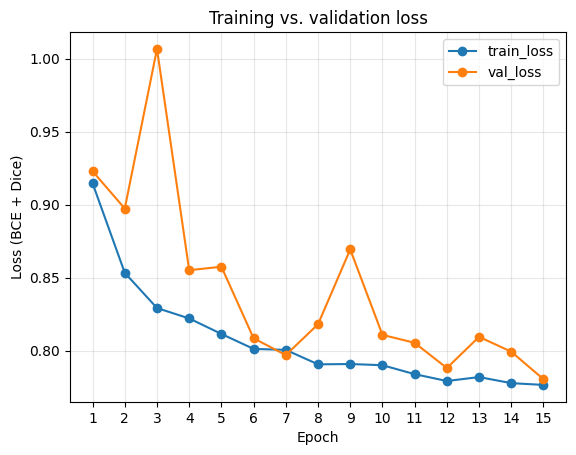

In [9]:
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_loss']) + 1)

plt.plot(epochs, history['train_loss'], marker='o', label='train_loss')
plt.plot(epochs, history['val_loss'], marker='o', label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (BCE + Dice)')
plt.title('Training vs. validation loss')
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Inference on unseen `TEST_PATH` images

`TEST_PATH` has no labels (no CSV), so `CloudSegmentationImage` can't decode
masks for it from a `DataFrame`. Instead, `predict_mask_stack()` runs the
trained model on a raw image and thresholds its output into a 0/1 mask stack
- the same shape `CloudSegmentationImage.get_mask_stack()` produces for
labeled images. That means `CloudSegmentationImage.from_image_and_masks()`
and therefore `display_masks_overlay()` work on model *predictions* just as
well as on ground truth.

Since a pixel/image can contain several cloud types at once (multi-label,
see above), "detected" below means: for that cloud type, the predicted mask
covers at least `MIN_DETECTION_AREA` pixels - not a single yes/no over the
whole image.

## 002f507.jpg - detected: **gravel**

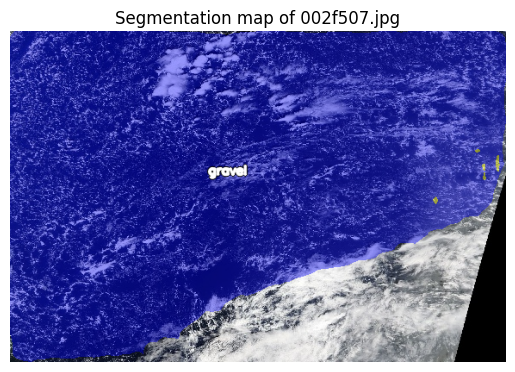

## 0035ae9.jpg - detected: **fish, gravel, sugar**

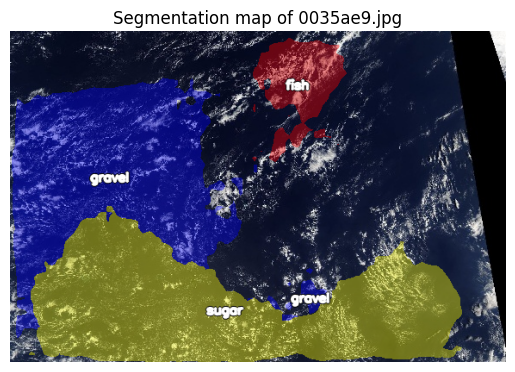

## 0038327.jpg - detected: **fish, flower, sugar**

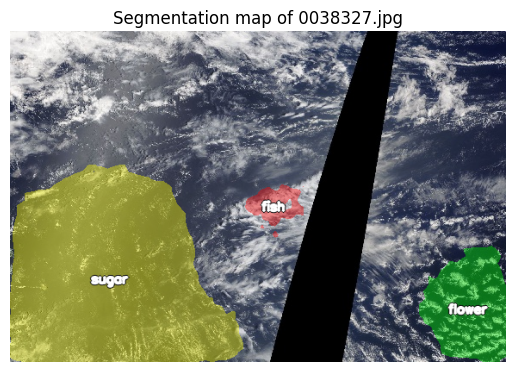

## 004f759.jpg - detected: **fish, flower, sugar**

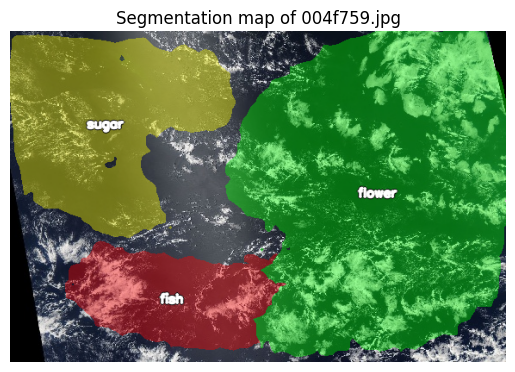

## 005ba08.jpg - detected: **gravel**

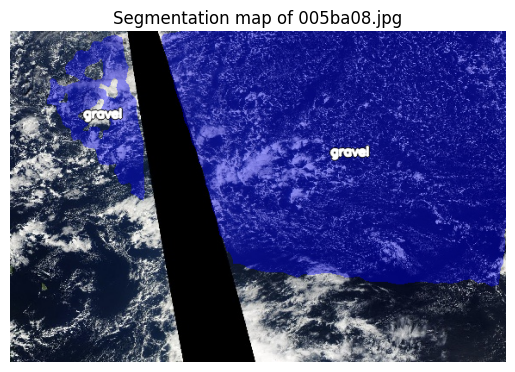

In [10]:
import cv2
from IPython.display import Markdown, display

from src.data.cloud_segmentation_image import (
    LABEL_CLASS_IDS,
    CloudSegmentationImage,
)
from src.models.predict_model import detected_labels, predict_mask_stack
from src.visualization.image_display import display_masks_overlay

NUM_TEST_IMAGES_TO_SHOW = 5
label_names = list(LABEL_CLASS_IDS.keys())

test_image_paths = sorted(TEST_PATH.iterdir())[:NUM_TEST_IMAGES_TO_SHOW]

for image_path in test_image_paths:
    image_bgr = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    mask_stack = predict_mask_stack(model_pspnet, image_rgb, device)
    labels = detected_labels(mask_stack, label_names)

    csi_pred = CloudSegmentationImage.from_image_and_masks(
        image_rgb=image_rgb,
        mask_stack=mask_stack,
        image_name=image_path.name,
        image_path=image_path.parent,
    )

    detected_str = ', '.join(labels) if labels else 'none'
    display(Markdown(f'## {image_path.name} - detected: **{detected_str}**'))
    display_masks_overlay(csi_pred)
